LAB1

In [1]:
#آمنة الاهدل    446000596
#حنين الحارثي   446005953
#لمى القرني    446003538
#لانا الغامدي    446001223

In [2]:
import pandas as pd

In [3]:
df=pd.read_csv("/kaggle/input/datasets/aliiihussain/amazon-sales-dataset/amazon_sales_dataset.csv")

In [4]:
df.head()

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue
0,1,2022-04-13,2637,Books,128.75,10,4,North America,UPI,3.5,443,115.88,463.52
1,2,2023-03-12,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40
2,3,2022-09-28,3670,Sports,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64
4,5,2022-03-13,1717,Beauty,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72


In [5]:
df.shape # أستخدمها لما أبي أعرف عدد الصفوف و الأعمدة 

(50000, 13)

In [6]:
df.info() # استخدمتها عشان أعرف أسماء الأعمدة و نوع البيانات اللي فيها 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          50000 non-null  int64  
 1   order_date        50000 non-null  object 
 2   product_id        50000 non-null  int64  
 3   product_category  50000 non-null  object 
 4   price             50000 non-null  float64
 5   discount_percent  50000 non-null  int64  
 6   quantity_sold     50000 non-null  int64  
 7   customer_region   50000 non-null  object 
 8   payment_method    50000 non-null  object 
 9   rating            50000 non-null  float64
 10  review_count      50000 non-null  int64  
 11  discounted_price  50000 non-null  float64
 12  total_revenue     50000 non-null  float64
dtypes: float64(4), int64(5), object(4)
memory usage: 5.0+ MB


In [7]:
df.describe() #ملخص إحصائي للبيانات

,order_id,product_id,price,discount_percent,quantity_sold,rating,review_count,discounted_price,total_revenue
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,25000.500000,2986.848740,252.507260,13.340700,2.999400,2.996316,249.329280,218.886566,657.331475
std,14433.901067,1156.374535,143.025544,9.850694,1.415401,1.154295,144.251981,127.317681,526.223968
min,1.000000,1000.000000,5.010000,0.000000,1.000000,1.000000,0.000000,3.530000,3.840000
25%,12500.750000,1983.000000,127.840000,5.000000,2.000000,2.000000,125.000000,109.680000,240.320000
50%,25000.500000,2983.000000,252.970000,10.000000,3.000000,3.000000,250.000000,215.805000,505.410000
75%,37500.250000,3989.000000,376.335000,20.000000,4.000000,4.000000,374.000000,322.702500,968.970000
max,50000.000000,4999.000000,499.990000,30.000000,5.000000,5.000000,499.000000,499.910000,2499.550000


LAB2

In [8]:
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

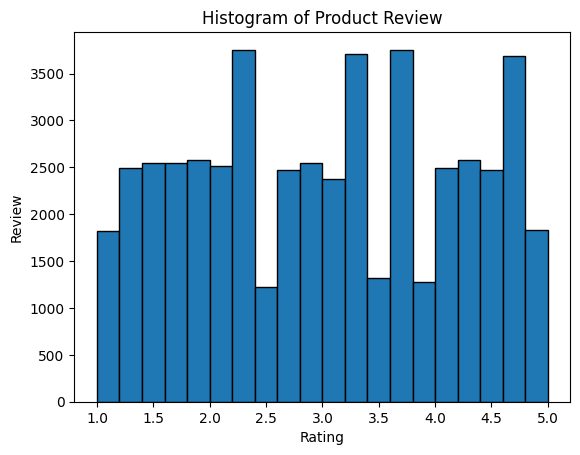

In [9]:
# Histogram رسم 
plt.hist(df["rating"],bins=20,edgecolor='black')     
plt.title("Histogram of Product Review") #عنوان الرسمة
plt.xlabel("Rating")
plt.ylabel("Review")
plt.show() #عرض الرسمة

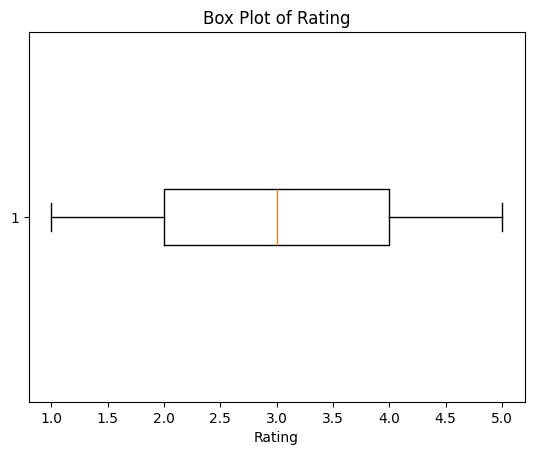

In [10]:
#Box Plot رسم   
plt.boxplot(df["rating"],vert=False) #لجعل الرسمة افقية
plt.title("Box Plot of Rating") #عنوان للرسمة
plt.xlabel("Rating")
plt.show() #عرض الرسمة 

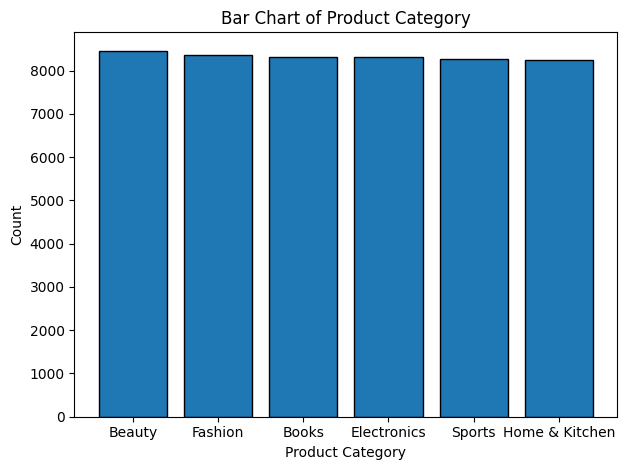

In [11]:
# حساب عدد تكرارات لكل فئة  
category_counts = df["product_category"].value_counts()
#Bar Chart رسم  
plt.bar(category_counts.index,category_counts.values,edgecolor='black')
plt.title("Bar Chart of Product Category") #عنوان للرسمة
plt.xlabel("Product Category")
plt.ylabel("Count")
plt.tight_layout() # ترتيب الرسومات
plt.show() #عرض الرسمة

In [12]:
#التحقق من وجود قيم مفقودة
df.isnull().sum()

order_id            0
order_date          0
product_id          0
product_category    0
price               0
discount_percent    0
quantity_sold       0
customer_region     0
payment_method      0
rating              0
review_count        0
discounted_price    0
total_revenue       0
dtype: int64

In [13]:
# التحقق من وجود صفوف مكررة
df.duplicated().sum()

np.int64(0)

In [14]:
#One-Hot Encoding تحويل الأعمدة النصية إلى أرقام
df_encoded = pd.get_dummies(df)

#Feature scaling (StandardScaler)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_encoded)

# إرجاعها DataFrame
df_scaled = pd.DataFrame(df_scaled, columns=df_encoded.columns)

# عرض أول 5 صفوف
df_scaled.head()

,order_id,product_id,price,discount_percent,quantity_sold,rating,review_count,discounted_price,total_revenue,order_date_2022-01-01,...,product_category_Sports,customer_region_Asia,customer_region_Europe,customer_region_Middle East,customer_region_North America,payment_method_Cash on Delivery,payment_method_Credit Card,payment_method_Debit Card,payment_method_UPI,payment_method_Wallet
0,-1.732016,-0.302542,-0.865289,-0.339137,0.706945,0.436361,1.342600,-0.809060,-0.368310,-0.036631,...,-0.445011,-0.578151,-0.575872,-0.577504,1.730482,-0.497718,-0.497123,-0.499406,1.990302,-0.50331
1,-1.731947,-0.593973,0.350240,0.676030,1.413465,0.609628,1.564436,0.182172,1.051024,-0.036631,...,-0.445011,1.729652,-0.575872,-0.577504,-0.577874,-0.497718,2.011573,-0.499406,-0.502436,-0.50331
2,-1.731878,0.590776,1.701061,0.676030,-0.706097,1.216065,-0.459820,1.396155,0.258350,-0.036631,...,2.247133,-0.578151,1.736496,-0.577504,-0.577874,-0.497718,-0.497123,-0.499406,1.990302,-0.50331
3,-1.731808,-0.401992,0.835123,0.168447,0.706945,1.735868,-0.258781,0.764029,1.154099,-0.036631,...,-0.445011,-0.578151,-0.575872,1.731589,-0.577874,-0.497718,-0.497123,-0.499406,1.990302,-0.50331
4,-1.731739,-1.098140,-0.355375,-1.354304,0.706945,1.389333,0.406728,-0.135148,0.283891,-0.036631,...,-0.445011,-0.578151,-0.575872,1.731589,-0.577874,-0.497718,-0.497123,-0.499406,1.990302,-0.50331


In [15]:
# One-hot encoding for categorical column
df = pd.get_dummies(df, columns=["product_category"], drop_first=False)
df.head()

,order_id,order_date,product_id,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,product_category_Beauty,product_category_Books,product_category_Electronics,product_category_Fashion,product_category_Home & Kitchen,product_category_Sports
0,1,2022-04-13,2637,128.75,10,4,North America,UPI,3.5,443,115.88,463.52,False,True,False,False,False,False
1,2,2023-03-12,2300,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40,False,False,False,True,False,False
2,3,2022-09-28,3670,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28,False,False,False,False,False,True
3,4,2022-04-17,2522,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64,False,True,False,False,False,False
4,5,2022-03-13,1717,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72,True,False,False,False,False,False


In [16]:
#Feature scaling بالستاندرايز سكالنج
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_encoded)
df_scaled = pd.DataFrame(df_scaled, columns=df_encoded.columns)
df_scaled.head()

,order_id,product_id,price,discount_percent,quantity_sold,rating,review_count,discounted_price,total_revenue,order_date_2022-01-01,...,product_category_Sports,customer_region_Asia,customer_region_Europe,customer_region_Middle East,customer_region_North America,payment_method_Cash on Delivery,payment_method_Credit Card,payment_method_Debit Card,payment_method_UPI,payment_method_Wallet
0,-1.732016,-0.302542,-0.865289,-0.339137,0.706945,0.436361,1.342600,-0.809060,-0.368310,-0.036631,...,-0.445011,-0.578151,-0.575872,-0.577504,1.730482,-0.497718,-0.497123,-0.499406,1.990302,-0.50331
1,-1.731947,-0.593973,0.350240,0.676030,1.413465,0.609628,1.564436,0.182172,1.051024,-0.036631,...,-0.445011,1.729652,-0.575872,-0.577504,-0.577874,-0.497718,2.011573,-0.499406,-0.502436,-0.50331
2,-1.731878,0.590776,1.701061,0.676030,-0.706097,1.216065,-0.459820,1.396155,0.258350,-0.036631,...,2.247133,-0.578151,1.736496,-0.577504,-0.577874,-0.497718,-0.497123,-0.499406,1.990302,-0.50331
3,-1.731808,-0.401992,0.835123,0.168447,0.706945,1.735868,-0.258781,0.764029,1.154099,-0.036631,...,-0.445011,-0.578151,-0.575872,1.731589,-0.577874,-0.497718,-0.497123,-0.499406,1.990302,-0.50331
4,-1.731739,-1.098140,-0.355375,-1.354304,0.706945,1.389333,0.406728,-0.135148,0.283891,-0.036631,...,-0.445011,-0.578151,-0.575872,1.731589,-0.577874,-0.497718,-0.497123,-0.499406,1.990302,-0.50331


In [17]:
#minMaxScaler مع العرض حقه
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_encoded)
df_scaled = pd.DataFrame(df_scaled, columns=df_encoded.columns)
df_scaled.head()

,order_id,product_id,price,discount_percent,quantity_sold,rating,review_count,discounted_price,total_revenue,order_date_2022-01-01,...,product_category_Sports,customer_region_Asia,customer_region_Europe,customer_region_Middle East,customer_region_North America,payment_method_Cash on Delivery,payment_method_Credit Card,payment_method_Debit Card,payment_method_UPI,payment_method_Wallet
0,0.00000,0.409352,0.249990,0.333333,0.75,0.625,0.887776,0.226339,0.184188,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.00002,0.325081,0.601216,0.666667,1.00,0.675,0.951904,0.480579,0.483454,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.00004,0.667667,0.991535,0.666667,0.25,0.850,0.366733,0.791954,0.316319,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.00006,0.380595,0.741323,0.500000,0.75,1.000,0.424850,0.629820,0.505187,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.00008,0.179295,0.397329,0.000000,0.75,0.900,0.617234,0.399190,0.321704,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
